In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

path = "../../../../assets/datasets/2_KG_Kidney_Disease_Dataset/data/kidney_disease_dataset.csv"
target = "Target"
severity_order = ["Low_Risk", "Moderate_Risk", "High_Risk", "Severe_Disease"]

df = pd.read_csv(path, na_values=["?"])
for c in df.columns:
    if pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].str.strip()

df = df[df[target].isin(severity_order)].reset_index(drop=True)
assert df[target].nunique() == len(severity_order)
features = [c for c in df.columns if c != target]

In [2]:
def is_numeric(s):
    return pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)


def encode(s, name):
    if is_numeric(s):
        return s.astype(float).rename(name).to_frame()
    d = pd.get_dummies(s, prefix=name, dtype=float)
    d[s.isna()] = np.nan
    return d.iloc[:, [1]] if d.shape[1] == 2 else d


X = pd.concat([encode(df[c], c) for c in features], axis=1)
severity = df[target].map({c: i for i, c in enumerate(severity_order, start=1)}).rename("Severity")

print(f"Disease cases used: {len(df)}")
print(df[target].value_counts().reindex(severity_order).to_string())

Disease cases used: 4106
Target
Low_Risk          2054
Moderate_Risk      821
High_Risk          821
Severe_Disease     410


In [3]:
with np.errstate(invalid="ignore"):
    r = X.corrwith(severity).fillna(0.0)

n_used = X.notna().sum()
dof = n_used - 2
t = r * np.sqrt(dof / (1 - r ** 2))
result = pd.DataFrame({"r": r, "n_used": n_used, "t": t, "p": 2 * stats.t.sf(t.abs(), dof)})
result["significant"] = result["p"] < 0.05 / len(result)
result = result.reindex(r.abs().sort_values(ascending=False).index)
result.round(4)

,r,n_used,t,p,significant
Sugar in urine,0.0325,4106,2.0821,0.0374,False
Appetite (good/poor)_poor,-0.0262,4106,-1.6803,0.0930,False
Red blood cells in urine_normal,-0.0223,4106,-1.4271,0.1536,False
Family history of chronic kidney disease_yes,0.0211,4106,1.3489,0.1774,False
Hemoglobin level (gms),0.0203,4106,1.2975,0.1945,False
Serum phosphate level,0.0198,4106,1.2714,0.2036,False
Sodium level (mEq/L),-0.0190,4106,-1.2185,0.2231,False
Blood urea (mg/dl),-0.0181,4106,-1.1600,0.2461,False
Physical activity level_moderate,0.0164,4106,1.0477,0.2948,False
Cystatin C level,-0.0161,4106,-1.0321,0.3021,False


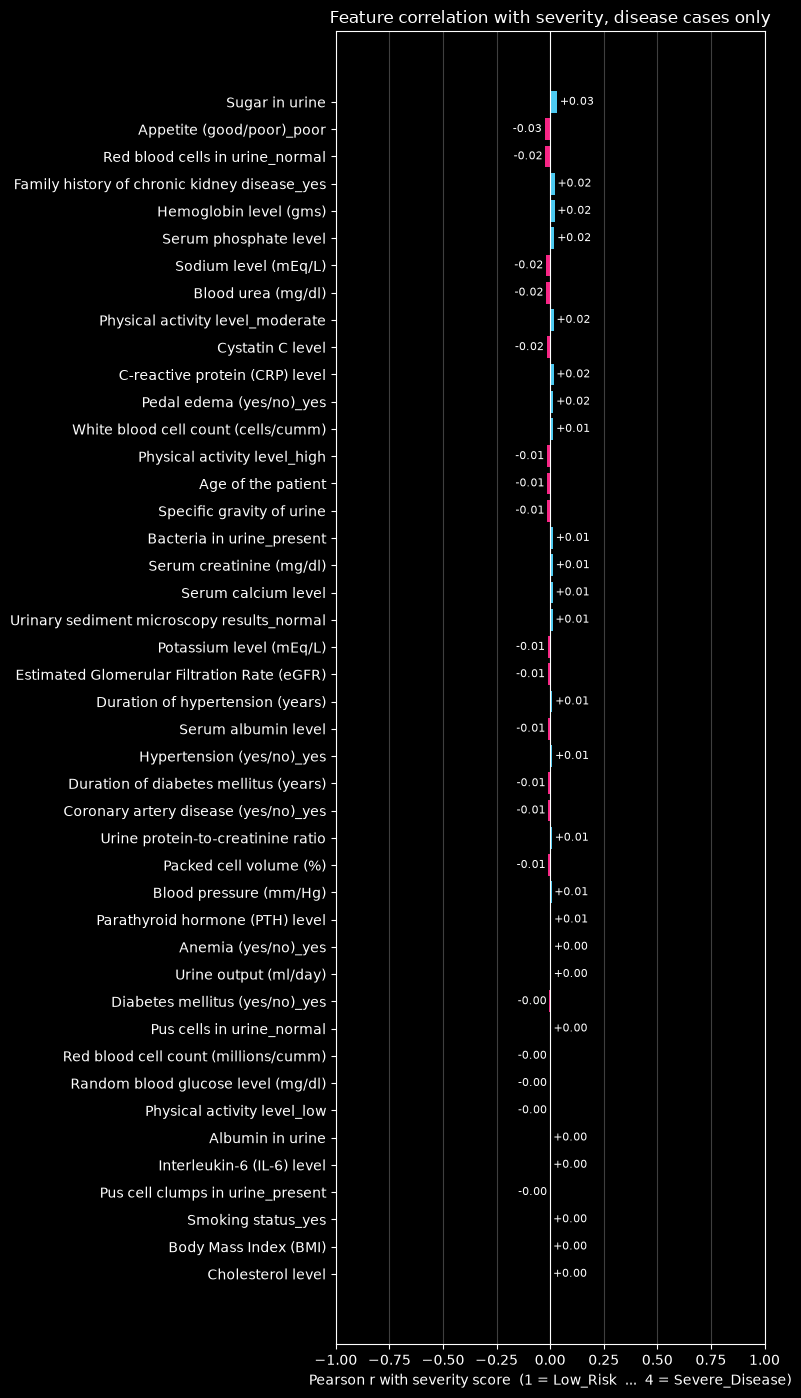

In [4]:
plt.style.use("dark_background")
r_plot = result["r"].iloc[::-1]

fig, ax = plt.subplots(figsize=(8, max(4, 0.32 * len(r_plot))))
bars = ax.barh(r_plot.index, r_plot.values, color=np.where(r_plot.values >= 0, "#4cc9f0", "#f72585").tolist())
ax.bar_label(bars, fmt="%+.2f", padding=2, fontsize=8)
ax.axvline(0, color="white", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel(f"Pearson r with severity score  (1 = {severity_order[0]}  ...  {len(severity_order)} = {severity_order[-1]})")
ax.set_title("Feature correlation with severity, disease cases only")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()